# Corpus de hojas: aprendizaje no supervisado y supervisado

---

## Descripción de la base de datos

El corpus de hojas fue construido por el equipo durante el curso. Las hojas fueron recolectadas a mano por Juan Pablo Martha, integrante del equipo, a inicios de octubre. Se incluyeron hojas de tres tipos de árbol: **Limón**, **Ocozote** y **Fresno**.

Cada hoja se fotografió junto a una regla, que sirvió como escala de referencia. Las medidas de la mayoría de las hojas se obtuvieron a partir de estas fotografías con ayuda de herramientas de inteligencia artificial (Gemini y ChatGPT); unas pocas se midieron directamente con la regla. El alto se midió desde el inicio de la hoja, sin contar el pecíolo.

La etiqueta de cada hoja corresponde al árbol del que fue recolectada. Cada hoja se representa con dos características numéricas:

- **Alto (cm):** longitud de la hoja, sin contar el pecíolo.
- **Ancho (cm):** ancho de la hoja.

La columna `ID hoja` es únicamente un identificador, por lo que no se utiliza como característica.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
datos = pd.read_csv("../data/hojasRazonamiento.csv", encoding="utf-8")

caracteristicas = ["Alto (cm)", "Ancho (cm)"]
columna_clase = "Árbol"

# Orden fijo de las clases: define la codificación 0, 1 y 2
# (este orden afecta al MAE de los modelos supervisados)
CLASES = ["Limón", "Fresno", "Ocozote"]

X = datos[caracteristicas].to_numpy()
y = datos[columna_clase].map({clase: i for i, clase in enumerate(CLASES)}).to_numpy()

# Verificar que se cargó el corpus de hojas completo
if X.shape != (150, 2):
    raise ValueError(
        f"Se esperaba X con forma (150, 2) y se obtuvo {X.shape}. "
        "Verifica que se cargó data/hojasRazonamiento.csv."
    )

if np.isnan(y.astype(float)).any() or datos.isna().any().any():
    raise ValueError("Existen etiquetas desconocidas o valores faltantes.")

# Colores fijos por clase, utilizados en todas las figuras
COLORES_CLASE = {
    "Limón": "forestgreen",
    "Fresno": "darkorange",
    "Ocozote": "royalblue"
}

# Colores para los clústeres (distintos a los de las clases)
COLORES_CLUSTER = [
    "mediumpurple", "teal", "goldenrod",
    "hotpink", "sienna", "slategray"
]

print("Tamaño de X:", X.shape)
print("Tamaño de y:", y.shape)
print("Clases (código):", {i: clase for i, clase in enumerate(CLASES)})
print("Características:", caracteristicas)
print("Valores faltantes:", datos.isna().sum().sum())

Tamaño de X: (150, 2)
Tamaño de y: (150,)
Clases (código): {0: 'Limón', 1: 'Fresno', 2: 'Ocozote'}
Características: ['Alto (cm)', 'Ancho (cm)']
Valores faltantes: 0


In [3]:
datos.head()

,ID hoja,Árbol,Alto (cm),Ancho (cm)
0,1,Limón,4.7,2.5
1,2,Limón,6.8,3.7
2,3,Limón,5.4,2.7
3,4,Limón,7.0,3.6
4,5,Limón,4.7,2.3


In [4]:
decimales = (datos[caracteristicas] * 10 % 1).abs().round(6)
pares_repetidos = datos.duplicated(subset=caracteristicas).sum()

print("Medidas con más de un decimal:", int((decimales > 0).sum().sum()))
print("Hojas con un par (Alto, Ancho) idéntico a otra hoja:", pares_repetidos)
print()
print("Rango de ID por clase:")
print(datos.groupby(columna_clase)["ID hoja"].agg(["min", "max"]).loc[CLASES])

Medidas con más de un decimal: 0
Hojas con un par (Alto, Ancho) idéntico a otra hoja: 10

Rango de ID por clase:
         min  max
Árbol            
Limón      1   50
Fresno   101  150
Ocozote   51  100


## Distribución por clase

In [5]:
distribucion = (
    datos[columna_clase]
    .value_counts()
    .reindex(CLASES)
    .rename("Número de hojas")
    .to_frame()
)

distribucion["Porcentaje (%)"] = (
    distribucion["Número de hojas"] / len(datos) * 100
).round(2)

print("Número total de hojas:", len(datos))
print("Número de clases:", len(CLASES))
distribucion

Número total de hojas: 150
Número de clases: 3


,Número de hojas,Porcentaje (%)
Árbol,,
Limón,50,33.33
Fresno,50,33.33
Ocozote,50,33.33


La base contiene **150 hojas** distribuidas en **3 clases** con **50 hojas cada una** (33.33 %). Al ser una base balanceada, ninguna clase domina el entrenamiento y las métricas con promedio macro dan el mismo peso a las tres clases.

## Estadísticas descriptivas por clase

Para cada clase se calculan la media, la desviación estándar, el mínimo y el máximo de las dos características.

In [6]:
estadisticas = (
    datos
    .groupby(columna_clase)[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .loc[CLASES]
    .round(2)
)

estadisticas = estadisticas.rename(
    columns={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    },
    level=1
)

estadisticas

Alto (cm)                              Ancho (cm)                 \
            Media Desv. estándar Mínimo Máximo      Media Desv. estándar   
Árbol                                                                      
Limón        6.02           0.89    4.3    7.6       3.05           0.45   
Fresno      10.94           1.85    7.6   14.3       3.45           0.73   
Ocozote     12.81           2.75    8.0   17.7      12.10           1.97   

                       
        Mínimo Máximo  
Árbol                  
Limón      2.2    3.9  
Fresno     2.1    4.8  
Ocozote    8.0   15.9

In [7]:
estadisticas_globales = (
    datos[caracteristicas]
    .agg(["mean", "std", "min", "max"])
    .rename(index={
        "mean": "Media",
        "std": "Desv. estándar",
        "min": "Mínimo",
        "max": "Máximo"
    })
    .round(2)
)

estadisticas_globales

,Alto (cm),Ancho (cm)
Media,9.93,6.20
Desv. estándar,3.48,4.37
Mínimo,4.30,2.10
Máximo,17.70,15.90


## Gráficas exploratorias

Todas las gráficas se presentan en el espacio original de las dos características, medidas en centímetros. No se aplica PCA a esta base.

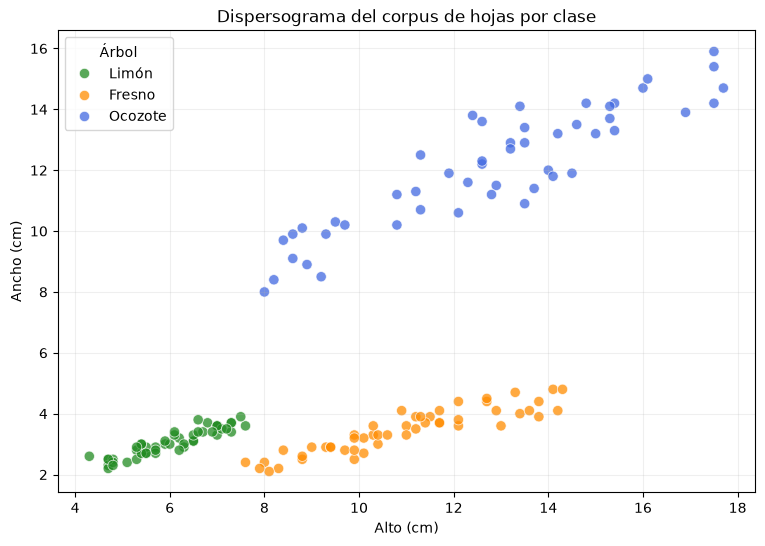

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Alto (cm)",
    y="Ancho (cm)",
    hue=columna_clase,
    hue_order=CLASES,
    palette=COLORES_CLASE,
    alpha=0.75,
    s=55
)

plt.title("Dispersograma del corpus de hojas por clase")
plt.xlabel("Alto (cm)")
plt.ylabel("Ancho (cm)")
plt.legend(title="Árbol")
plt.grid(alpha=0.2)
plt.show()

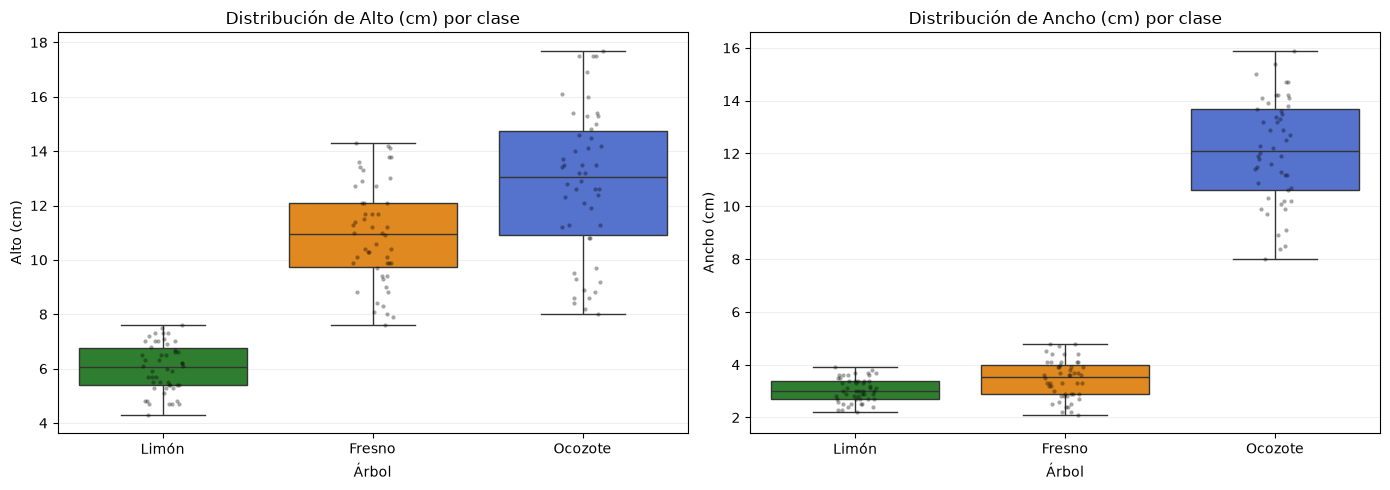

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, caracteristica in zip(axes, caracteristicas):
    sns.boxplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        hue=columna_clase,
        order=CLASES,
        hue_order=CLASES,
        palette=COLORES_CLASE,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=datos,
        x=columna_clase,
        y=caracteristica,
        order=CLASES,
        color="black",
        alpha=0.35,
        size=3,
        ax=ax
    )

    ax.set_title(f"Distribución de {caracteristica} por clase")
    ax.set_xlabel("Árbol")
    ax.set_ylabel(caracteristica)
    ax.grid(alpha=0.2, axis="y")

plt.tight_layout()
plt.show()

In [10]:
# Traslape de rangos entre clases para cada característica
for caracteristica in caracteristicas:
    print(f"{caracteristica}:")

    for i, clase_a in enumerate(CLASES):
        for clase_b in CLASES[i + 1:]:
            a = datos.loc[datos[columna_clase] == clase_a, caracteristica]
            b = datos.loc[datos[columna_clase] == clase_b, caracteristica]

            inicio = max(a.min(), b.min())
            fin = min(a.max(), b.max())

            if inicio <= fin:
                en_traslape = (
                    a.between(inicio, fin).sum()
                    + b.between(inicio, fin).sum()
                )
                print(
                    f"  {clase_a} y {clase_b}: traslape de {inicio:.1f} a {fin:.1f} cm "
                    f"({en_traslape} de {len(a) + len(b)} hojas dentro del traslape)"
                )
            else:
                print(f"  {clase_a} y {clase_b}: sin traslape")
    print()

Alto (cm):
  Limón y Fresno: traslape de 7.6 a 7.6 cm (2 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: traslape de 8.0 a 14.3 cm (83 de 100 hojas dentro del traslape)

Ancho (cm):
  Limón y Fresno: traslape de 2.2 a 3.9 cm (86 de 100 hojas dentro del traslape)
  Limón y Ocozote: sin traslape
  Fresno y Ocozote: sin traslape



In [11]:
# Relación entre alto y ancho dentro de cada clase
relacion = pd.DataFrame({
    "Correlación Alto-Ancho": datos.groupby(columna_clase).apply(
        lambda g: g["Alto (cm)"].corr(g["Ancho (cm)"]),
        include_groups=False
    ),
    "Proporción Alto/Ancho (media)": (
        datos["Alto (cm)"] / datos["Ancho (cm)"]
    ).groupby(datos[columna_clase]).mean()
}).loc[CLASES].round(2)

relacion

,Correlación Alto-Ancho,Proporción Alto/Ancho (media)
Árbol,,
Limón,0.92,1.98
Fresno,0.91,3.21
Ocozote,0.91,1.05


### Interpretación del análisis exploratorio

La gráfica de dispersión muestra que **Ocozote** se separa claramente de las otras dos clases por su ancho: sus hojas miden entre 8.0 y 15.9 cm de ancho, mientras que ninguna hoja de Limón o Fresno supera los 4.8 cm. No existe traslape en el ancho entre Ocozote y las demás clases.

**Limón** y **Fresno** se traslapan casi por completo en el ancho: 86 de sus 100 hojas se encuentran dentro del intervalo común de 2.2 a 3.9 cm. Su diferencia principal está en el alto: las hojas de Limón miden entre 4.3 y 7.6 cm y las de Fresno entre 7.6 y 14.3 cm, por lo que solamente coinciden en el valor de 7.6 cm (2 hojas). En consecuencia, la frontera entre ambas clases depende sobre todo del alto y se ubica alrededor de los 7.6 cm, donde ambas clases quedan muy próximas.

En el alto, Fresno y Ocozote sí presentan un traslape amplio (de 8.0 a 14.3 cm, con 83 de 100 hojas dentro del intervalo), pero esto no afecta su separación, porque el ancho las distingue por completo.

Ocozote es la clase con mayor dispersión en ambas variables (desviación estándar de 2.75 cm en el alto y 1.97 cm en el ancho), mientras que Limón es la más compacta (0.89 y 0.45 cm). Dentro de cada clase, el alto y el ancho están positivamente correlacionados: las hojas más largas también tienden a ser más anchas, con correlaciones de 0.92 en Limón, 0.91 en Fresno y 0.91 en Ocozote. La proporción alto/ancho promedio es de 1.05 en Ocozote (hojas casi tan anchas como largas), 1.98 en Limón y 3.21 en Fresno (hojas alargadas).

Las dos variables tienen escalas diferentes (desviación estándar global de 3.48 cm en el alto y 4.37 cm en el ancho), por lo que los métodos basados en distancias se aplicarán sobre las variables estandarizadas.

Las medidas se registraron con un decimal y 10 hojas comparten exactamente el mismo par (alto, ancho) con otra hoja. Estos valores repetidos se conservan, ya que corresponden a hojas distintas y son esperables con una resolución de 0.1 cm. Finalmente, los identificadores están ordenados por clase (Limón del 1 al 50, Ocozote del 51 al 100 y Fresno del 101 al 150), por lo que las particiones de validación cruzada deberán barajar los datos.